# Question 3: Operations monitoring and transfer investigation

Which data each part uses matters here: (a) and (c) use the **full cleaned data**,
(b) uses the **sampled TRANSFER rows**. The assignment is explicit about this.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import csc1105 as cs

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.6 | numpy 2.5.4


In [2]:
analysis_df = cs.load_clean(verbose=False)
sample, X = cs.sample_matrix(analysis_df)
print("full cleaned rows:", f"{len(analysis_df):,}   sample rows: {len(sample):,}")

full cleaned rows: 1,720,181   sample rows: 2,000


## 3(a) The step-by-type count matrix, from the FULL cleaned data

In [3]:
M_df = pd.crosstab(analysis_df["step"], analysis_df["transactionType"]).sort_index()
M = M_df.to_numpy(dtype=float)
steps = M_df.index.to_numpy()
types = list(M_df.columns)

print("M shape :", M.shape, "  (S steps x 5 types)")
print("rows    : steps", steps.min(), "to", steps.max())
print("columns :", types)
M_df.head()

M shape : (144, 5)   (S steps x 5 types)
rows    : steps 0 to 143
columns : ['DEBIT', 'DEPOSIT', 'PAYMENT', 'TRANSFER', 'WITHDRAWAL']


transactionType,DEBIT,DEPOSIT,PAYMENT,TRANSFER,WITHDRAWAL
step,,,,,
0,0,0,4005,2402,0
1,3,2088,4035,2556,5
2,1,449,4042,2689,1
3,0,4,3997,2652,0
4,0,0,4006,2614,0


In [4]:
# step counts as a matrix-by-vector product: c = M @ 1_5
c = M @ np.ones(M.shape[1])
print("c = M @ 1_5 has shape", c.shape)
print("check against a direct row sum:", np.allclose(c, M.sum(axis=1)))

order = np.argsort(c)[::-1]
print()
print("three busiest steps:")
for r in order[:3]:
    t = int(np.argmax(M[r]))
    print(f"  step {steps[r]:>4}  {c[r]:>10,.0f} transactions"
          f"   dominant type: {types[t]} ({M[r, t]:,.0f})")

c = M @ 1_5 has shape (144,)
check against a direct row sum: True

three busiest steps:
  step   18      30,489 transactions   dominant type: DEPOSIT (13,927)
  step  139      29,853 transactions   dominant type: DEPOSIT (12,711)
  step   19      28,997 transactions   dominant type: DEPOSIT (12,571)


saved C:\Math 2026 repo\CSC-1105-Maths-for-CS\figures\step_counts.png


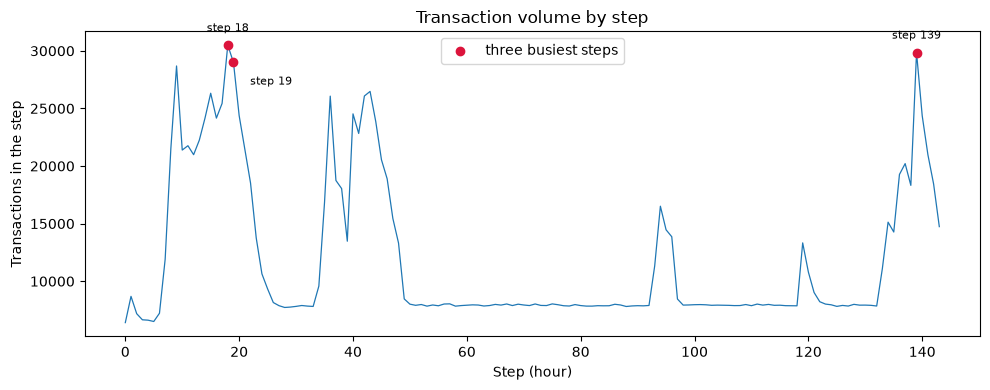

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(steps, c, linewidth=0.9)
top3 = order[:3]
ax.scatter(steps[top3], c[top3], color="crimson", zorder=5, label="three busiest steps")
# steps 18 and 19 are neighbours, so stagger the labels to keep both readable
placed = []
for r in top3:
    x, y = steps[r], c[r]
    dx, dy, ha = 0, 10, "center"
    if any(abs(x - px) <= 3 for px in placed):
        dx, dy, ha = 12, -16, "left"
    ax.annotate(f"step {x}", (x, y), textcoords="offset points",
                xytext=(dx, dy), ha=ha, fontsize=8)
    placed.append(x)
ax.set_xlabel("Step (hour)")
ax.set_ylabel("Transactions in the step")
ax.set_title("Transaction volume by step")
ax.legend()
cs.savefig(fig, "step_counts.png")
plt.show()

## 3(b) Balance changes, from the SAMPLED transfer rows

Row 1 of `B` selects `newBalInitiator - oldBalInitiator`; row 2 does the same
for the recipient. `Y = X_T @ B.T` is the row form of `B @ x_i`: X_T is m x 5
and B.T is 5 x 2, so Y is m x 2.

In [6]:
# use the type name exactly as it appears in the data
transfer_name = [t for t in types if "TRANSFER" in str(t).upper()]
print("transfer category found:", transfer_name)
tr = sample["transactionType"] == transfer_name[0]

X_T = sample.loc[tr, cs.COLS].to_numpy(dtype=float)
print("sampled transfers:", X_T.shape)

Y = X_T @ cs.B.T
print("Y shape:", Y.shape)

# verification by direct subtraction, as the assignment requires
direct = np.column_stack([X_T[:, 2] - X_T[:, 1], X_T[:, 4] - X_T[:, 3]])
print("matches direct subtraction:", np.allclose(Y, direct))

transfer category found: ['TRANSFER']
sampled transfers: (688, 5)
Y shape: (688, 2)
matches direct subtraction: True


In [7]:
a = X_T[:, 0]
r_I = Y[:, 0] + a          # initiator should lose exactly a
r_R = Y[:, 1] - a          # recipient should gain exactly a

mismatch = (np.abs(r_I) > cs.TOL) | (np.abs(r_R) > cs.TOL)
print(f"tolerance declared : {cs.TOL} monetary units")
print(f"transfers examined : {mismatch.size:,}")
print(f"mismatching        : {int(mismatch.sum()):,}  ({mismatch.mean():.4%})")
print()
print("largest |r_I|:", f"{np.abs(r_I).max():,.4f}")
print("largest |r_R|:", f"{np.abs(r_R).max():,.4f}")

tolerance declared : 0.01 monetary units
transfers examined : 688
mismatching        : 141  (20.4942%)

largest |r_I|: 77,814.0700
largest |r_R|: 77,814.0700


In [8]:
# mismatch proportion by label, WITH the group counts beside it
lab = sample.loc[tr, "isFraud"].to_numpy()
rows = []
for value in sorted(pd.unique(lab)):
    g = lab == value
    rows.append({"isFraud": value,
                 "transfers in group": int(g.sum()),
                 "mismatch proportion": float(mismatch[g].mean()) if g.sum() else np.nan})
pd.DataFrame(rows)

,isFraud,transfers in group,mismatch proportion
0,0,464,0.196121
1,1,224,0.223214


If fraudulent transfers mismatch more often, the
balance identity is a usable signal, because it can be checked at the moment of
processing without knowing the label. If the proportions are similar, the
finding is that this check does not separate the groups. The question does not
require the comparison to come out any particular way.

## 3(c) Fraud count and rate by step, from the FULL cleaned data

In [9]:
per_step = analysis_df.groupby("step").agg(
    count=("isFraud", "size"),
    fraud=("isFraud", "sum"))
per_step["rate"] = per_step["fraud"] / per_step["count"]

print("highest fraud rates:")
print(per_step.sort_values("rate", ascending=False).head(8))
print()
print("note the count column: a rate from very few transactions is unstable")

highest fraud rates:
      count  fraud      rate
step                        
0      6407   1177  0.183705
3      6653   1205  0.181121
2      7182   1265  0.176135
4      6620   1158  0.174924
5      6506   1106  0.169997
60     7914   1302  0.164519
113    7988   1293  0.161868
82     7840   1268  0.161735

note the count column: a rate from very few transactions is unstable


saved C:\Math 2026 repo\CSC-1105-Maths-for-CS\figures\fraud_rate_by_step.png


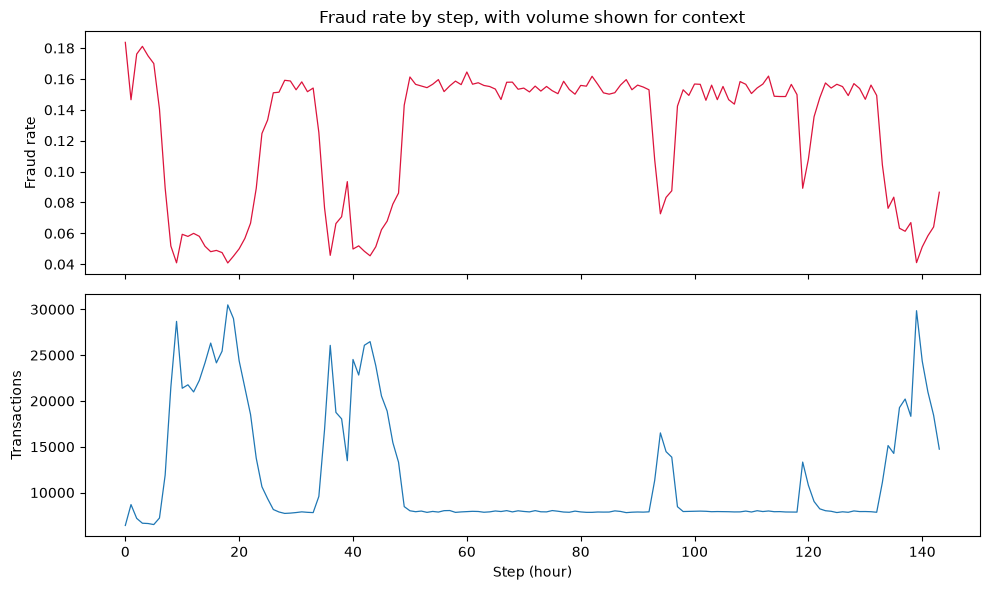

In [10]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(per_step.index, per_step["rate"], linewidth=0.9, color="crimson")
ax1.set_ylabel("Fraud rate")
ax1.set_title("Fraud rate by step, with volume shown for context")
ax2.plot(per_step.index, per_step["count"], linewidth=0.9)
ax2.set_ylabel("Transactions")
ax2.set_xlabel("Step (hour)")
cs.savefig(fig, "fraud_rate_by_step.png")
plt.show()

In [11]:
busiest = per_step["count"].idxmax()
riskiest = per_step["rate"].idxmax()
pd.DataFrame({
    "busiest step": per_step.loc[busiest],
    "highest fraud rate step": per_step.loc[riskiest],
}).T

,count,fraud,rate
busiest step,30489.0,1245.0,0.040834
highest fraud rate step,6407.0,1177.0,0.183705


## 3(c) and 3(d) findings

**Busy is a capacity problem.** More transactions and more queries, so the
response is staff, processing capacity and a longer service window. Adding fraud
controls there would slow many legitimate transactions for no gain.

**Risky is a control problem.** Volume may be ordinary but a larger share is
fraudulent, so the response is tighter checks and review before settlement.
Adding staff would not reduce fraud; throughput is not the difficulty.

**Two recommendations** follow, one on capacity and one on risk. Each names what
to do and when, quotes the figure above that supports it, and says how the
effect will be measured afterwards.